# Домашнее задание 2. Линейная регрессия и градиентный спуск

## Математические методы анализа данных

В этом задании вы:

- **Обучите линейные модели** для предсказания цены подержанного автомобиля на данных из ДЗ-1: `LinearRegression`, `Lasso`, `ElasticNet`, `Ridge`, подберете гиперпараметры на кросс-валидации, примените one-hot-кодирование категорий;
- **Реализуете градиентный спуск** своими руками, посмотрите, как он ведёт себя на выпуклой и невыпуклой функции, и обучите с помощью него линейную регрессию.

**Дедлайн: 17 октября 2026, 23:59 (МСК).** Работы после дедлайна не принимаются.

**Максимальный балл за задание — 10.**

| Часть | Баллы |
|---|---|
| 0. Подготовка данных | 0 |
| 1. Линейная регрессия | 5 |
| 2. Градиентный спуск | 5 |
| **Итого** | **10** |

## <font color="red">Правила выполнения</font>

- Сдаём файл `.ipynb` через LMS. Перед сдачей перезапустите ноутбук и выполните все ячейки сверху вниз (*Kernel → Restart & Run All*, в Colab — *Среда выполнения → Перезапустить сеанс и выполнить все*). Ноутбук должен отработать без ошибок, все выводы и графики должны сохраниться.
- Если пользуетесь LLM или готовыми решениями из интернета, напишите об этом рядом с кодом: какая модель или какой ресурс. Решение нужно понимать полностью.
- После дедлайна 10–15 % работ случайно выбираются для онлайн-защиты: попросим объяснить решение. Если автор не может объяснить свой код, задание обнуляется.
- Оцениваются и код, и текстовые ответы. Если нет одного из двух, балл за пункт снижается.
- В каждом пункте сказано, на какой выборке работать: train или test. Всё, что «обучается» (scaler, кодировщик, модель), обучаем **только на train**, а к test только применяем.
- Ячейки с `assert` не меняйте: они проверяют, что у вас получились данные нужного размера или верные функции.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

# Часть 0. Подготовка данных (0 баллов)

Работаем с теми же данными, что в ДЗ-1: объявления о продаже подержанных автомобилей в Индии. Целевая переменная (таргет) — `selling_price`, цена в рупиях.

| Признак | Что означает |
|---|---|
| `name` | марка и модель |
| `year` | год выпуска |
| `selling_price` | цена продажи в рупиях — **таргет** |
| `km_driven` | пробег, км |
| `fuel` | тип топлива |
| `seller_type` | кто продаёт: частное лицо или дилер |
| `transmission` | коробка передач |
| `owner` | какой по счёту владелец |
| `mileage` | сколько км машина проезжает на литре топлива (kmpl) или килограмме газа (km/kg) |
| `engine` | объём двигателя, см³ |
| `max_power` | мощность, л. с. (bhp) |
| `seats` | число мест |

Ниже — готовая предобработка по шагам ДЗ-1:
- убираем единицы измерения
- удаляем `torque`
- чиним `km_driven`
- заполняем пропуски медианами по train
- приводим `seats` к `int`
- удаляем дубли.

**Просто запустите ячейку.** Даже если в ДЗ-1 вы делали иначе, используйте этот код: тогда у всех одинаковые данные и ответы можно сверять.

In [2]:
URL = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_1/Data/'
df_train = pd.read_csv(URL + 'new_cars_train.csv')
df_test = pd.read_csv(URL + 'new_cars_test.csv')

for df in [df_train, df_test]:
    # '23.4 kmpl' -> 23.4, '1248 CC' -> 1248, '74 bhp' -> 74; если числа нет -> NaN
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce')
    # torque удаляем, как в ДЗ-1
    df.drop(columns='torque', inplace=True)
    # в km_driven встречаются '-' и пропуски -> NaN
    df['km_driven'] = pd.to_numeric(df['km_driven'], errors='coerce')

# пропуски заполняем медианами, посчитанными только по train
cols_with_na = ['km_driven', 'mileage', 'engine', 'max_power', 'seats']
train_medians = df_train[cols_with_na].median()
df_train[cols_with_na] = df_train[cols_with_na].fillna(train_medians)
df_test[cols_with_na] = df_test[cols_with_na].fillna(train_medians)

df_train['seats'] = df_train['seats'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)

# дубли по признакам (без таргета) удаляем только в train, оставляем первую строку
feature_cols = [col for col in df_train.columns if col != 'selling_price']
df_train = df_train.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)

print('train:', df_train.shape, ' test:', df_test.shape)

train: (5843, 12)  test: (1000, 12)


In [3]:
assert df_train.shape == (5843, 12) and df_test.shape == (1000, 12)
assert df_train.isna().sum().sum() == 0 and df_test.isna().sum().sum() == 0

df_train.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5
2,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5
3,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000.0,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5


# Часть 1. Линейная регрессия (5 баллов)

Качество моделей оцениваем двумя метриками:

- **MSE** (среднеквадратичная ошибка, mean squared error): $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2.$$ Чем меньше, тем лучше. Измеряется в «рупиях в квадрате».
- **$R^2$** (коэффициент детерминации): $$R^2 = 1 - \dfrac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2},$$ где $\bar y$ — среднее таргета **на той же выборке**, на которой считаем метрику. Показывает, какую долю разброса цен объясняет модель; $R^2 = 1$ — идеальные прогнозы.

**Здесь и далее для каждой обученной модели выводите $R^2$ и MSE на train и на test**, даже если в пункте об этом не сказано: иначе непонятно, стало ли лучше.

### Задание 1.1. Числовые признаки (0.25 балла)

Начнём с модели только на числовых признаках: `year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`.

Запишите в `X_train` и `X_test` эти столбцы из `df_train` и `df_test`, а в `y_train` и `y_test` — таргет `selling_price` из тех же таблиц.

In [4]:
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

X_train = df_train[num_features]
y_train = df_train['selling_price']
X_test = df_test[num_features]
y_test = df_test['selling_price']

In [5]:
assert X_train.shape == (5843, 6) and X_test.shape == (1000, 6)
assert y_train.shape == (5843,) and y_test.shape == (1000,)

### Задание 1.2. Первая модель (0.5 балла)

1. **(0.15)** Напишите функцию `print_metrics(model, X_train, y_train, X_test, y_test)`: она получает уже обученную модель и печатает $R^2$ и MSE на train и на test. Дальше пользуйтесь ей для всех моделей.
2. **(0.15)** Обучите линейную регрессию `LinearRegression` с параметрами по умолчанию на train. Выведите метрики.
3. **(0.2)** Ответьте на вопросы:
   - Какую долю разброса цен на test объясняет модель?
   - Сравните train и test по $R^2$ и по MSE. Почему выводы по двум метрикам расходятся? Подсказка: сравните разброс цен `y_train.std()` и `y_test.std()`.
   - Посчитайте $\text{RMSE} = \sqrt{\text{MSE}}$ на test. Какова типичная ошибка прогноза в рупиях? Много это или мало по сравнению с медианной ценой на train?

In [6]:
# 1

from sklearn.metrics import mean_squared_error, r2_score

def print_metrics(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    print(f'Train MSE: {train_mse}')
    print(f'Test MSE: {test_mse}')
    print(f'Train R2: {train_r2}')
    print(f'Test R2: {test_r2}')


In [7]:
# 2

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print_metrics(model, X_train, y_train, X_test, y_test)

Train MSE: 116851699646.59648
Test MSE: 233395049519.10342
Train R2: 0.5921371915881415
Test R2: 0.593974503824225


In [8]:
# 3
from sklearn.metrics import root_mean_squared_error

print(f"y_train.std(): {y_train.std()}")
print(f"y_test.std(): {y_test.std()}")

y_train_pred = model.predict(X_train)

print(f"Train RMSE: {root_mean_squared_error(y_train, y_train_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred)}")

print(f'median: {y_train.median()}')
print(f"rmse / median: {root_mean_squared_error(y_test, y_pred) / y_train.median()}")




y_train.std(): 535300.4778164638
y_test.std(): 758553.8607099976
Train RMSE: 341835.7787689821
Test RMSE: 483109.7696374018
median: 408000.0
rmse / median: 1.1840925726406908


**Ваш ответ:**


Какую долю разброса цен на test объясняет модель?

    Примерно 59%.

Сравните train и test по R² и MSE. Почему выводы по двум метрикам расходятся?

    Судя по стандартным отклонениям y_train.std() и y_test.std(), разброс цен в test больше, чем в train. Поэтому MSE на test может быть выше, даже при том, что R² примерно такой же, как на train (и даже немного выше).

Посчитайте $\text{RMSE} = \sqrt{\text{MSE}}$ на test. Какова типичная ошибка прогноза в рупиях? Много это или мало по сравнению с медианной ценой на train?

    На test RMSE = 483 110 рупий - примерно 118% от медианной цены на train (408 000 рупий). Следовательно, типичная ошибка прогноза больше медианной стоимости автомобиля, поэтому ошибка довольно большая.




### Задание 1.3. Может ли $R^2$ быть отрицательным? (0.25 балла)

Часто говорят, что $R^2$ лежит от 0 до 1. Для линейной регрессии это верно **на обучающей выборке**: там модель не хуже константы, равной среднему. На новых данных $R^2$ бывает и меньше нуля. Проверим.

1. **(0.1)** Сделайте «константную модель»: каждому объекту test предскажите одно и то же число — среднюю цену на train `y_train.mean()`. Посчитайте $R^2$ этой модели на test.
2. **(0.15)** Ответьте: почему получилось меньше нуля? Посмотрите на формулу $R^2$: с каким прогнозом на test сравнивается модель? Что в итоге означает $R^2 < 0$?

In [9]:

y_test_pred_const = np.full_like(y_test, y_train.mean())

r2_const = r2_score(y_test, y_test_pred_const)
print(f"R² for constant model: {r2_const}")

R² for constant model: -0.015678539700324734


**Ваш ответ:**

Получилось меньше нуля, потому что R2 сравнивает модель с прогнозом среднего значения y_test. Мы предсказывали среднее по y_train, поэтому результат оказался хуже этого базового прогноза. R2 < 0 означает, что модель работает хуже предсказания среднего на test (абсолютно неадекватна).

### Задание 1.4. Стандартизация и важность признаков (0.5 балла)

1. **(0.1)** Стандартизируйте признаки с помощью `StandardScaler`: обучите его (`fit`) **только на train**, затем преобразуйте (`transform`) и train, и test. Результаты запишите в `X_train_scaled` и `X_test_scaled`.
2. **(0.2)** Обучите `LinearRegression` на `X_train_scaled` и выведите метрики. Изменились ли они по сравнению с 1.2? Объясните почему.
3. **(0.2)** Выведите коэффициенты модели вместе с названиями признаков. Какой признак сильнее всего влияет на цену (по модулю коэффициента)? Почему сравнивать коэффициенты так можно только после стандартизации? Подсказка: сравните коэффициент при `km_driven` в моделях из 1.2 и 1.4.

In [10]:
#1

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
#2

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)
y_test_pred_scaled = model_scaled.predict(X_test_scaled)

print_metrics(model_scaled, X_train_scaled, y_train, X_test_scaled, y_test)


Train MSE: 116851699646.59616
Test MSE: 233395049519.09775
Train R2: 0.5921371915881426
Test R2: 0.593974503824235


In [12]:
coef_table_scaled = pd.DataFrame(
    data=model_scaled.coef_, 
    index=X_train.columns, 
    columns=['Коэффициент']
)

coef_table = pd.DataFrame(
    data=model.coef_, 
    index=X_train.columns, 
    columns=['Коэффициент']
)
print('Коэффициенты модели с масштабированными признаками:')
print(coef_table_scaled, end = '\n\n')
print('Коэффициенты модели без масштабирования признаков:')
print(coef_table)



Коэффициенты модели с масштабированными признаками:
             Коэффициент
year       152898.498205
km_driven  -43953.853566
mileage     28791.816950
engine      61371.072884
max_power  322550.136077
seats      -23441.054866

Коэффициенты модели без масштабирования признаков:
            Коэффициент
year       37333.892365
km_driven     -0.732218
mileage     7226.170950
engine       126.413400
max_power  10197.850490
seats     -23864.530151


**Ваш ответ:**

2. метрики не изменились, потому что линейная регрессия без регуляризации инвариантна к линейному масштабированию признаков, коэффиценты изменяются но предсказания остаются прежними

3. Сильнее всего на цену влияет max_power, так как у него наибольший по модулю коэффициент: примерно 322 550.
   
   Сравнивать коэффициенты можно только после стандартизации, потому что признаки измеряются в разных единицах и масштабах. Например, коэффициент km_driven изменился с −0.73 за один километр до −43 954. Веса зависят не только от влияния признаков на целевую переменную, но и от их масштаба.

### Задание 1.5. Lasso (0.25 балла)

Lasso — линейная регрессия с L1-регуляризацией. В sklearn она минимизирует $\frac{1}{2n}\|y - Xw\|^2 + \alpha \sum_j |w_j|$. Из-за штрафа часть весов может стать ровно нулём: модель сама отбирает признаки.

1. **(0.1)** Обучите `Lasso` с параметрами по умолчанию на `X_train_scaled`. Выведите метрики и коэффициенты.
2. **(0.15)** Занулились ли какие-нибудь веса? Предположите почему. Подсказка: по умолчанию `alpha=1`; сравните это число с масштабом коэффициентов из 1.4.

In [13]:
from sklearn.linear_model import Lasso
model_lasso = Lasso()
model_lasso.fit(X_train_scaled, y_train)
y_test_pred_lasso = model_lasso.predict(X_test_scaled)
y_train_pred_lasso = model_lasso.predict(X_train_scaled)

print_metrics(model_lasso, X_train_scaled, y_train, X_test_scaled, y_test)

coef_table = pd.DataFrame(
    data=model_lasso.coef_, 
    index=X_train.columns, 
    columns=['Коэффициент']
) 

print("\n", coef_table)

Train MSE: 116851699656.70386
Test MSE: 233395718994.16306
Train R2: 0.5921371915528624
Test R2: 0.5939733391725162

              Коэффициент
year       152898.319080
km_driven  -43952.724732
mileage     28789.935092
engine      61366.246387
max_power  322551.016342
seats      -23438.180227


**Ваш ответ:**

Никакие веса не занулились в связи с тем что стандартное значение alpha в Lasso слишком мало (alpha=1) в сравнении с коэффициентами признаков.

### Задание 1.6. Подбор `alpha` для Lasso по сетке (0.5 балла)

Гиперпараметр `alpha` нельзя подбирать по test: тогда test перестанет быть «новыми данными». Подбираем его на кросс-валидации (cross-validation) внутри train.

1. **(0.2)** С помощью [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) подберите `alpha` для `Lasso` на `X_train_scaled`: 5 фолдов (`cv=5`), метрика $R^2$ (`scoring='r2'`), сетка для `alpha` — `np.logspace(1, 5, 9)` (9 значений от 10 до 100 000).
2. **(0.15)** Ответьте:
   - Сколько моделей обучил `GridSearchCV`? Учтите, что после перебора лучшая модель ещё раз обучается на всём train (параметр `refit=True` по умолчанию).
   - Какой `alpha` оказался лучшим? Какие веса занулились при нём?
3. **(0.15)** Выведите метрики лучшей модели (`best_estimator_`) на train и test. Стала ли она лучше `LinearRegression` из 1.4? Почему регуляризация здесь почти не помогает? Подсказка: вспомните, от чего защищает регуляризация, и сравните $R^2$ на train и test в 1.2.

In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'alpha': np.logspace(1, 5, 9),
}

grid = GridSearchCV(estimator=Lasso(), param_grid=param_grid, cv=5, scoring='r2')
grid.fit(X_train_scaled, y_train)




,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'alpha': array([1.0000...00000000e+05])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues 

In [15]:
best_model = grid.best_estimator_

coefficients = pd.Series(
    best_model.coef_,
    index=X_train.columns
)

print("Лучший alpha:", grid.best_params_['alpha'])
print("Веса:")
print(coefficients)

Лучший alpha: 10000.0
Веса:
year         151900.854500
km_driven    -32542.494056
mileage        9300.594878
engine        17881.075858
max_power    329047.292676
seats            -0.000000
dtype: float64


In [16]:
print_metrics(best_model, X_train_scaled, y_train, X_test_scaled, y_test)

Train MSE: 117719059815.03975
Test MSE: 240615768163.70963
Train R2: 0.5891097306673696
Test R2: 0.5814129868749038


**Ваш ответ:**

GridsearchCV обучил 46 моделей (по 5 фолдам для каждой из 9 значений alpha + одна модель для лучшего параметра).
Лучшим параметром оказался alpha = 10000. Занулился коэффицент при признаке seats.

Стала ли она лучше `LinearRegression` из 1.4? Почему регуляризация здесь почти не помогает? Подсказка: вспомните, от чего защищает регуляризация, и сравните $R^2$ на train и test в 1.2.

Нет, не стала, а даже показала себя немного хуже, потому что регуляризация защищает от переобучения, а в данной задаче модель `LinearRegression` и так не переобучалась, R2 на train и test были очень близки.





### Задание 1.7. ElasticNet (0.25 балла)

[`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) совмещает L1- и L2-регуляризацию. В sklearn он минимизирует
$$\frac{1}{2n}\|y - Xw\|^2 + \alpha\,\rho\,\|w\|_1 + \frac{\alpha\,(1 - \rho)}{2}\,\|w\|_2^2,$$
где $\rho$ — параметр `l1_ratio`: при $\rho = 1$ получается Lasso, при $\rho = 0$ — только L2-штраф, как в Ridge.

1. **(0.15)** Подберите `alpha` и `l1_ratio` для `ElasticNet` с помощью `GridSearchCV` на `X_train_scaled`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-3, 2, 6)`, для `l1_ratio` — `[0.1, 0.3, 0.5, 0.7, 0.9]`.
2. **(0.1)** Ответьте: сколько моделей обучил `GridSearchCV`? Какие гиперпараметры у лучшей модели? Выведите её метрики на train и test.

In [17]:
from sklearn.linear_model import ElasticNetCV

param_grid_elastic = {
    'alpha': np.logspace(-3, 2, 6),
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

grid_elastic = GridSearchCV(estimator=ElasticNet(), param_grid=param_grid_elastic, cv=5, scoring='r2')

grid_elastic.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",ElasticNet()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.e-03...e+01, 1.e+02]), 'l1_ratio': [0.1, 0.3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printe

In [18]:
best_model_elastic = grid_elastic.best_estimator_

coefficients = pd.Series(
    best_model_elastic.coef_,
    index=X_train.columns
)

print(f'Коэффициенты модели ElasticNet:\n{coefficients}\n')
print(f'Лучшие параметры модели ElasticNet:\n{grid_elastic.best_params_}\n')

print_metrics(best_model_elastic, X_train_scaled, y_train, X_test_scaled, y_test)


Коэффициенты модели ElasticNet:
year         149686.865728
km_driven    -45248.518774
mileage       25675.020541
engine        73245.690216
max_power    299315.961652
seats        -25271.025350
dtype: float64

Лучшие параметры модели ElasticNet:
{'alpha': np.float64(0.1), 'l1_ratio': 0.5}

Train MSE: 117178726919.36
Test MSE: 239723536113.39578
Train R2: 0.590995725419485
Test R2: 0.5829651575900883


**Ваш ответ:**

GridSearchCV обучил 151 модель: 30 комбинаций гиперпараметров × 5 фолдов и ещё одну итоговую модель на всём train.
Лучшие гиперпараметры: alpha = 0.1, l1_ratio = 0.5.
Метрики лучшей модели:
- Train: MSE ≈ 117.18 млрд, R² ≈ 0.591
- Test: MSE ≈ 239.72 млрд, R² ≈ 0.583
- Train R2 ≈ 0.591
- Test R2 ≈ 0.583

### Задание 1.8. Добавляем категориальные признаки (0.75 балла)

Дадим модели больше информации — категориальные признаки `fuel`, `seller_type`, `transmission`, `owner`. Признак `seats` тоже закодируем как категорию: разных значений у него мало, и нет причин считать, что каждое следующее место меняет цену на одну и ту же сумму. Столбец `name` пока не используем: в нём слишком много уникальных значений (обработаем его в задании 1.11).

1. **(0.25)** Закодируйте `fuel`, `seller_type`, `transmission`, `owner`, `seats` методом one-hot (OHE): `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`. Обучите кодировщик на train, примените к train и test. Параметр `handle_unknown='ignore'` нужен на случай, если в test встретится категория, которой не было в train: она закодируется нулями вместо ошибки.
2. **(0.25)** Соберите итоговые матрицы признаков `X_train_all` и `X_test_all`: стандартизированные числовые признаки `year`, `km_driven`, `mileage`, `engine`, `max_power` (новый `StandardScaler`, обученный на train) + OHE-столбцы. Склеить матрицы по столбцам можно через `np.hstack([A, B])`.
3. **(0.25)** Ответьте: зачем `drop='first'`? Что без него случилось бы с матрицей признаков линейной регрессии? Подсказка: dummy trap, «ловушка фиктивных переменных».

In [19]:
from sklearn.preprocessing import OneHotEncoder

cat_features = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
num_features_2 = ['year', 'km_driven', 'mileage', 'engine', 'max_power']

scaler = StandardScaler()

ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

X_train_cat = ohe.fit_transform(df_train[cat_features])
X_test_cat = ohe.transform(df_test[cat_features])

X_train_num = scaler.fit_transform(df_train[num_features_2])
X_test_num = scaler.transform(df_test[num_features_2])

X_train_all = np.hstack([X_train_num, X_train_cat])
X_test_all = np.hstack([X_test_num, X_test_cat])

In [20]:
# ваш код здесь

In [21]:
assert X_train_all.shape == (5843, 23) and X_test_all.shape == (1000, 23)

**Ваш ответ:**

Без drop='first' создается N столбцов, где N - количество уникальных категорий и возникает линейная зависимость между ними, что может привести к проблемам при обучении моделей линейной регрессии. Использование drop='first' позволяет избежать этой проблемы, исключая первый столбец и тем самым устраняя линейную зависимость.

### Задание 1.9. Ridge на всех признаках (0.5 балла)

1. **(0.25)** Подберите `alpha` для гребневой регрессии `Ridge` (L2-регуляризация) с помощью `GridSearchCV` на `X_train_all`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-2, 3, 11)`.
2. **(0.25)** Какой `alpha` лучший? Выведите метрики лучшей модели на train и test. Удалось ли улучшить качество по сравнению с моделями только на числовых признаках (1.2–1.7)?

In [22]:
param_grid = {
    'alpha': np.logspace(-2, 3, 11)
}

grid_ridge = GridSearchCV(Ridge(), param_grid, cv=5, scoring='r2')
grid_ridge.fit(X_train_all, y_train)
print(f'Лучшие параметры: {grid_ridge.best_params_}')
print_metrics(grid_ridge, X_train_all, y_train, X_test_all, y_test)


Лучшие параметры: {'alpha': np.float64(3.1622776601683795)}
Train MSE: 96821657497.18845
Test MSE: 206651380789.84805
Train R2: 0.6620506739625796
Test R2: 0.6404991040148889


**Ваш ответ:**
лучший alpha: np.float64(3.1622776601683795)
Да, удалось улучшить качество по сравнению с предыдущими моделями.

### Задание 1.10. Бизнес-метрика (0.5 балла)

Заказчику непонятны $R^2$ и MSE. Он предлагает свою метрику — **долю «хороших» прогнозов**: прогноз хороший, если отличается от реальной цены не больше чем на 15 % в любую сторону, то есть $|\hat y_i - y_i| \le 0.15 \cdot y_i$.

1. **(0.2)** Реализуйте функцию `business_metric(y_true, y_pred)`, которая возвращает эту долю (число от 0 до 1).
2. **(0.2)** Посчитайте её **на test** для моделей из 1.2, 1.6, 1.7 и 1.9 и сведите в таблицу вместе с $R^2$ на test. Какая модель лучше с точки зрения заказчика? Совпадает ли она с лучшей по $R^2$?
3. **(0.1)** Сколько прогнозов на test получились отрицательными у каждой модели? Что это говорит о линейной модели для цен?

In [23]:
def business_metric(y_true, y_pred):
    y_true = np.asarray(y_true)
    return np.mean(np.abs(y_pred - y_true) <= 0.15 * y_true)

In [24]:
best_model_ridge = grid_ridge.best_estimator_

business_metric_1_2 = business_metric(y_test, model.predict(X_test))
business_metric_1_6 = business_metric(y_test, best_model.predict(X_test_scaled))
business_metric_1_7 = business_metric(y_test, best_model_elastic.predict(X_test_scaled))
business_metric_1_9 = business_metric(y_test, best_model_ridge.predict(X_test_all))


# это написал codex GPT-5.6 Sol
results_1_10 = pd.DataFrame({
    'Модель': ['1.2 LinearRegression', '1.6 Lasso', '1.7 ElasticNet', '1.9 Ridge'],
    'Бизнес-метрика': [business_metric_1_2, business_metric_1_6, business_metric_1_7, business_metric_1_9],
    'R2 на test': [
        r2_score(y_test, model.predict(X_test)),
        r2_score(y_test, best_model.predict(X_test_scaled)),
        r2_score(y_test, best_model_elastic.predict(X_test_scaled)),
        r2_score(y_test, best_model_ridge.predict(X_test_all))
    ]
})

results_1_10

,Модель,Бизнес-метрика,R2 на test
0,1.2 LinearRegression,0.335,0.593975
1,1.6 Lasso,0.348,0.581413
2,1.7 ElasticNet,0.340,0.582965
3,1.9 Ridge,0.328,0.640499


In [25]:
# это написал codex GPT-5.6 Sol

predictions = {
    '1.2': model.predict(X_test),
    '1.6': best_model.predict(X_test_scaled),
    '1.7': best_model_elastic.predict(X_test_scaled),
    '1.9': best_model_ridge.predict(X_test_all)
}

for name, y_pred in predictions.items():
    print(name, np.sum(y_pred < 0))

1.2 71
1.6 68
1.7 66
1.9 63


**Ваш ответ:**

Лучшей по бизнес-метрике оказалась Lasso из 1.6 - 0.348. По R² лучшей оказалась Ridge из 1.9 - 0.640, поэтому результаты не совпали.

Отрицательных прогнозов: 1.2 - 71, 1.6 - 68, 1.7 - 66, 1.9 - 63. Это показывает, что линейные модели могут предсказывать невозможные отрицательные цены, потому что их прогнозы не ограничены снизу.

### Задание 1.11. Марка из `name` (0.25 балла)

Вместо того чтобы выбрасывать `name`, достаньте из него марку автомобиля — первое слово: `'Maruti Swift Dzire VDI'` → `'Maruti'`. Добавьте марку к категориальным признакам, закодируйте их OHE, как в 1.8, и повторите подбор `Ridge` из 1.9 (та же сетка, `cv=5`). Как изменились $R^2$ и бизнес-метрика на test? Зачем здесь понадобился `handle_unknown='ignore'`?

In [26]:
df_train['brand'] = df_train['name'].str.split().str[0]
df_test['brand'] = df_test['name'].str.split().str[0]

df_train[['name', 'brand']].head()

,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Hyundai i20 Sportz Diesel,Hyundai
3,Maruti Swift VXI BSIII,Maruti
4,Hyundai Xcent 1.2 VTVT E Plus,Hyundai


In [27]:
cat_features_brand = cat_features + ['brand']

ohe_brand = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat_brand = ohe_brand.fit_transform(
    df_train[cat_features_brand]
)

X_test_cat_brand = ohe_brand.transform(
    df_test[cat_features_brand]
)

c:\Users\Максим\OneDrive\Рабочий стол\ml hse\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [28]:
X_train_brand = np.hstack([X_train_num, X_train_cat_brand])
X_test_brand = np.hstack([X_test_num, X_test_cat_brand])

print(X_train_brand.shape)
print(X_test_brand.shape)

(5843, 52)
(1000, 52)


In [29]:
grid_ridge_brand = GridSearchCV( Ridge(), param_grid, cv=5, scoring='r2')

grid_ridge_brand.fit(X_train_brand, y_train)

model_brand = grid_ridge_brand.best_estimator_

print('Лучший alpha:', grid_ridge_brand.best_params_)
print_metrics(model_brand, X_train_brand, y_train, X_test_brand, y_test)
print(f'Бизнес-метрика Train: {business_metric(y_train, model_brand.predict(X_train_brand))}')
print(f'Бизнес-метрика Test: {business_metric(y_test, model_brand.predict(X_test_brand))}')

Лучший alpha: {'alpha': np.float64(1.0)}
Train MSE: 65699465702.50306
Test MSE: 126071338736.9278
Train R2: 0.7706805406029713
Test R2: 0.7806801045280288
Бизнес-метрика Train: 0.39277768269724456
Бизнес-метрика Test: 0.404


**Ваш ответ:**

После добавления марки автомобиля R² на test вырос с 0.640 до 0.781, а бизнес-метрика - с 0.328 до 0.404.

handle_unknown='ignore' нужен, потому что в test могут встретиться марки, которых не было в train. Без него OHE выдал бы ошибку, а с ним неизвестная марка кодируется нулями.

### Задание 1.12. Логарифм таргета (0.5 балла)

Цены сильно скошены вправо: много дешёвых машин и немного очень дорогих. Линейной модели часто проще предсказывать не саму цену, а её логарифм.

1. **(0.2)** Подберите `Ridge`, как в 1.9 (на `X_train_all`, та же сетка, `cv=5`), но обучайте на таргете $\log y$ (`np.log(y_train)`).
2. **(0.15)** Прогнозы переведите обратно в рупии через `np.exp` и посчитайте на test $R^2$, MSE, бизнес-метрику и число отрицательных прогнозов.
3. **(0.15)** Сравните с 1.9. Почему логарифм помог? Почему отрицательных прогнозов теперь быть не может?

In [30]:
grid_ridge_log = GridSearchCV(Ridge(), param_grid, cv=5, scoring='r2')

grid_ridge_log.fit(X_train_all, np.log(y_train))
model_log = grid_ridge_log.best_estimator_

y_train_pred_log = np.exp(model_log.predict(X_train_all))
y_test_pred_log = np.exp(model_log.predict(X_test_all))

print('Лучший alpha:', grid_ridge_log.best_params_)

print('Train MSE:', mean_squared_error(y_train, y_train_pred_log))
print('Test MSE:', mean_squared_error(y_test, y_test_pred_log))

print('Train R2:', r2_score(y_train, y_train_pred_log))
print('Test R2:', r2_score(y_test, y_test_pred_log))

print('Бизнес-метрика Test:', business_metric(y_test, y_test_pred_log))
print('Отрицательных прогнозов:', np.sum(y_test_pred_log < 0))

Лучший alpha: {'alpha': np.float64(3.1622776601683795)}
Train MSE: 52200790964.3535
Test MSE: 102741798310.87485
Train R2: 0.8177967349346833
Test R2: 0.8212653193668107
Бизнес-метрика Test: 0.426
Отрицательных прогнозов: 0


**Ваш ответ:**

R² на test вырос с 0.640 до 0.821, MSE снизился с 206.65 млрд до 102.74 млрд, бизнес-метрика выросла с 0.328 до 0.426.

Логарифм уменьшил влияние дорогих автомобилей. Отрицательных прогнозов нет, потому что np.exp всегда возвращает положительное значение.

# Часть 2. Градиентный спуск (5 баллов)

В машинном обучении мы минимизируем **функцию потерь** $L(w)$, где $w$ — вектор параметров (весов) модели. Например, для линейной регрессии это MSE из части 1.

**Градиентный спуск** (gradient descent, GD) — численный метод минимизации. Градиент $\nabla L(w)$ показывает направление наискорейшего роста функции, поэтому шагаем в обратную сторону:
$$w_{k+1} = w_k - \eta\,\nabla L(w_k),$$
где $w_k$ — параметры на шаге $k$, а $\eta > 0$ — **шаг обучения** (learning rate).

Что нужно решить при реализации:

1. **Инициализация** — из какой точки $w_0$ начинаем.
2. **Шаг обучения $\eta$.** Слишком маленький — спуск идёт очень медленно; слишком большой — «перепрыгивает» минимум и может разойтись. Это главный гиперпараметр спуска, дальше мы изучим его влияние.
3. **Критерий остановки.** Делаем не больше $N$ итераций, но останавливаемся раньше, если норма градиента $\|\nabla L(w_k)\|$ стала меньше порога `tol`: в минимуме гладкой функции градиент равен нулю. Бывают и другие критерии: малое изменение параметров $\|w_{k+1} - w_k\|$ или значения функции $|L(w_{k+1}) - L(w_k)|$.
4. **История обучения.** На каждой итерации сохраняем параметры $w_k$, значение $L(w_k)$ и норму градиента. По ним рисуем траекторию спуска и **кривую обучения** — график значения функции по итерациям.

**Выпуклые и невыпуклые функции.** У выпуклой функции любой локальный минимум — глобальный, поэтому при разумном шаге спуск из любой точки придёт к минимуму. Реальные функции потерь (например, у нейросетей) часто невыпуклые: у них бывают «овраги», плато и локальные минимумы. Посмотрим на спуск по функциям обоих типов.

### Задание 2.1. Функции и их градиенты (0.5 балла)

Реализуйте две функции двух переменных и их градиенты. На вход подаётся `params` — массив NumPy `[x, y]`. Функция возвращает число, градиент — массив `np.array([df/dx, df/dy])`.

1. **Вытянутая квадратичная функция** (выпуклая): $f(x, y) = x^2 + 4y^2$. Минимум — в точке $(0, 0)$.
2. **[Функция Розенброка](https://ru.wikipedia.org/wiki/%D0%A4%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D1%8F_%D0%A0%D0%BE%D0%B7%D0%B5%D0%BD%D0%B1%D1%80%D0%BE%D0%BA%D0%B0)** (Rosenbrock function, невыпуклая): $f(x, y) = (a - x)^2 + b\,(y - x^2)^2$ с параметрами $a$ и $b$ (по умолчанию $a = 1$, $b = 100$). Минимум — в точке $(a, a^2)$, на дне длинного изогнутого «оврага».

Производные посчитайте на бумаге. Следующая ячейка сверит ваши градиенты с численными. Баллы: квадратичная функция — 0.2, функция Розенброка — 0.3.

In [31]:
def quadratic_loss(params):
    """f(x, y) = x^2 + 4y^2"""
    x, y = params
    return x**2 + 4*y**2


def quadratic_grad(params):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([2*x, 8*y])


def rosenbrock_loss(params, a=1, b=100):
    """f(x, y) = (a - x)^2 + b(y - x^2)^2"""
    x, y = params
    return (a - x)**2 + b*(y - x**2)**2


def rosenbrock_grad(params, a=1, b=100):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([-2*(a - x) - 4*b*x*(y - x**2), 2*b*(y - x**2)])

In [32]:
# Проверка: сравниваем ваши градиенты с численными (центральная разностная производная)
def numerical_grad(f, params, h=1e-6):
    grad = np.zeros(len(params))
    for i in range(len(params)):
        step = np.zeros(len(params))
        step[i] = h
        grad[i] = (f(params + step) - f(params - step)) / (2 * h)
    return grad


test_points = [np.array([1.0, 2.0]), np.array([-1.2, 1.0]), np.array([0.5, -0.3])]
for p in test_points:
    assert np.allclose(quadratic_grad(p), numerical_grad(quadratic_loss, p), rtol=1e-4), f'quadratic_grad, точка {p}'
    assert np.allclose(rosenbrock_grad(p), numerical_grad(rosenbrock_loss, p), rtol=1e-4), f'rosenbrock_grad, точка {p}'
    # lambda — короткая безымянная функция: здесь это Розенброк с a=2, b=10
    assert np.allclose(rosenbrock_grad(p, a=2, b=10),
                       numerical_grad(lambda q: rosenbrock_loss(q, a=2, b=10), p), rtol=1e-4), \
        f'rosenbrock_grad с a=2, b=10, точка {p}'
assert quadratic_loss(np.array([0.0, 0.0])) == 0 and rosenbrock_loss(np.array([1.0, 1.0])) == 0
print('Всё верно: градиенты совпадают с численными.')

Всё верно: градиенты совпадают с численными.


### Задание 2.2. Класс `GradientDescent` (1 балл)

Допишите класс градиентного спуска. Он принимает:

- `learning_rate` — шаг обучения $\eta_0$;
- `n_iterations` — максимальное число итераций;
- `decay` — параметр расписания шага (пригодится в задании 2.5). Если `decay=None`, шаг постоянный: $\eta_k = \eta_0$. Если задано число, шаг уменьшается по правилу **inverse time decay**: $\eta_k = \dfrac{\eta_0}{1 + \text{decay}\cdot k}$, где $k$ — номер итерации (0, 1, 2, …);
- `tol` — порог для критерия остановки: если норма градиента стала меньше `tol`, останавливаемся. Если `tol=None`, делаем все `n_iterations` итераций.

Метод `fit(loss_fn, grad_fn, initial_params)` запускает спуск из точки `initial_params` и возвращает найденные параметры. В словарь `self.history` записываются параметры, значение функции и норма градиента **в каждой посещённой точке, включая стартовую**, а также шаг обучения на каждой итерации. Норму вектора считайте через `np.linalg.norm`.

Баллы: вычисления на итерации и шаг спуска — 0.5; остановка по `tol` — 0.25; расписание шага — 0.25.

In [33]:
class GradientDescent:
    """Градиентный спуск с историей обучения.

    learning_rate : float — базовый шаг обучения eta_0
    n_iterations  : int — максимальное число итераций
    decay         : float или None — параметр inverse time decay (None — шаг постоянный)
    tol           : float или None — останавливаемся, когда норма градиента < tol
    """

    def __init__(self, learning_rate=0.01, n_iterations=100, decay=None, tol=None):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.decay = decay
        self.tol = tol

    def fit(self, loss_fn, grad_fn, initial_params):
        self.history = {'params': [], 'loss': [], 'grad_norm': [], 'lr': []}
        params = np.array(initial_params, dtype=float)

        # n_iterations + 1: точку после последнего шага тоже записываем в историю
        for k in range(self.n_iterations + 1):
            loss = loss_fn(params)
            grad = grad_fn(params)
            grad_norm = np.linalg.norm(grad)

            self.history['params'].append(params.copy())
            self.history['loss'].append(loss)
            self.history['grad_norm'].append(grad_norm)

            # --- критерии остановки ---
            if k == self.n_iterations:  # итерации закончились
                break
            if not np.isfinite(loss):   # спуск разошёлся: значения улетели в бесконечность
                break
            if self.tol is not None and grad_norm < self.tol:
                break

            # --- шаг обучения на итерации k ---
            if self.decay is None:
                lr_k = self.learning_rate
            else:
                lr_k = self.learning_rate / (1 + self.decay * k)
            self.history['lr'].append(lr_k)

            # --- шаг градиентного спуска ---
            params = params - lr_k * grad

        return params

In [34]:
# Проверка класса на квадратичной функции
gd = GradientDescent(learning_rate=0.1, n_iterations=100, tol=1e-6)
final = gd.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(final, [0, 0], atol=1e-6), 'спуск не пришёл в минимум (0, 0)'
assert np.allclose(gd.history['params'][0], [1.0, 1.0]), 'в истории нет стартовой точки'
assert gd.history['grad_norm'][-1] < 1e-6 and len(gd.history['loss']) < 101, 'не сработала остановка по tol'

gd_decay = GradientDescent(learning_rate=0.1, n_iterations=3, decay=0.5)
gd_decay.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(gd_decay.history['lr'], [0.1, 0.1 / 1.5, 0.1 / 2]), 'расписание шага работает неверно'
assert len(gd_decay.history['params']) == 4, 'в истории должны быть старт и 3 шага'
print('Класс работает верно.')

Класс работает верно.


### Функции для графиков (готовые)

Две готовые функции на [plotly](https://plotly.com/python/): графики можно приближать, вращать и наводить на точки. Разбираться в коде не обязательно, достаточно понимать, что функции принимают:

- `plot_gd_2d(loss_fn, history_dict, x_range, y_range, title, min_point)` — линии уровня функции и траектории спуска, вид сверху;
- `plot_gd_3d(...)` с теми же аргументами — поверхность функции и траектории на ней в 3D.

`history_dict` — словарь `{подпись: gd.history}`, например `{'lr=0.1': gd.history}`. `x_range`, `y_range` — сетки значений по осям (`np.linspace`), `min_point` — точка минимума для отметки на графике. Траектории, которые ушли за пределы графика, обрезаются, а очень длинные прореживаются. Щелчок по подписи в легенде прячет траекторию, двойной щелчок оставляет только её — пригодится, когда траектории накладываются друг на друга.

Если вместо графика появилась ошибка про `nbformat`, выполните `%pip install nbformat` и перезапустите ядро.

In [35]:
def _prepare_trajectory(history, x_range, y_range, max_points=3000):
    """Траектория (T, 2): обрезаем на первом выходе за рамку графика и прореживаем длинные."""
    traj = np.array(history['params'], dtype=float)
    inside = (np.isfinite(traj).all(axis=1)
              & (traj[:, 0] >= x_range.min()) & (traj[:, 0] <= x_range.max())
              & (traj[:, 1] >= y_range.min()) & (traj[:, 1] <= y_range.max()))
    left_frame = not inside.all()
    if left_frame:
        traj = traj[:np.argmin(inside)]  # до первой точки за рамкой
    if len(traj) > max_points:  # прореживаем, последнюю точку оставляем обязательно
        step = int(np.ceil(len(traj) / max_points))
        if step % 2 == 0:
            step += 1  # нечётный шаг: колебания «туда-обратно» не пропадут при прореживании
        traj = traj[np.unique(np.r_[np.arange(0, len(traj), step), len(traj) - 1])]
    return traj, left_frame


def _surface(loss_fn, x_range, y_range):
    """Значения функции на сетке: Z[i, j] = f(x_range[j], y_range[i])."""
    return np.array([[loss_fn(np.array([x, y])) for x in x_range] for y in y_range])


def _starts_and_min(history_dict, min_point):
    """Стартовые точки всех траекторий (без повторов) и точка минимума."""
    starts = {tuple(np.round(h['params'][0], 6)) for h in history_dict.values()}
    return sorted(starts), min_point


def plot_gd_2d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Линии уровня функции + траектории спуска (вид сверху).
    Линии уровня рисуем для log(1 + f): так лучше виден «овраг» функции Розенброка."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Contour(x=x_range, y=y_range, z=np.log1p(Z), colorscale='Viridis',
                               ncontours=30, showscale=False, opacity=0.8, hoverinfo='skip'))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        fig.add_trace(go.Scatter(x=traj[:, 0], y=traj[:, 1], mode='lines+markers',
                                 name=label + (' (ушла за рамку)' if left_frame else ''),
                                 marker=dict(size=4), line=dict(width=2)))
    starts, min_point = _starts_and_min(history_dict, min_point)
    fig.add_trace(go.Scatter(x=[s[0] for s in starts], y=[s[1] for s in starts], mode='markers',
                             name='Старт', marker=dict(size=12, symbol='x', color='black')))
    if min_point is not None:
        fig.add_trace(go.Scatter(x=[min_point[0]], y=[min_point[1]], mode='markers', name='Минимум',
                                 marker=dict(size=14, symbol='star', color='red')))
    fig.update_layout(title=title, xaxis_title='x', yaxis_title='y', height=600,
                      xaxis=dict(range=[x_range.min(), x_range.max()], constrain='domain'),
                      yaxis=dict(range=[y_range.min(), y_range.max()], constrain='domain',
                                 scaleanchor='x', scaleratio=1))  # одинаковый масштаб осей
    fig.show()


def plot_gd_3d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Поверхность функции + траектории спуска в 3D."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Surface(x=x_range, y=y_range, z=Z, colorscale='Viridis',
                               opacity=0.7, showscale=False))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        z = [loss_fn(p) for p in traj]
        fig.add_trace(go.Scatter3d(x=traj[:, 0], y=traj[:, 1], z=z, mode='lines+markers',
                                   name=label + (' (ушла за рамку)' if left_frame else ''),
                                   marker=dict(size=3), line=dict(width=4)))
    if min_point is not None:
        z_min = loss_fn(np.array(min_point, dtype=float))
        fig.add_trace(go.Scatter3d(x=[min_point[0]], y=[min_point[1]], z=[z_min], mode='markers',
                                   name='Минимум', marker=dict(size=6, symbol='diamond', color='red')))
    fig.update_layout(title=title, height=700,
                      scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
    fig.show()

### Задание 2.3. Шаг обучения на квадратичной функции (0.75 балла)

Изучим, как шаг $\eta$ влияет на спуск по функции $f(x, y) = x^2 + 4y^2$.

1. **(0.2)** Для каждого шага из списка `learning_rates` запустите `GradientDescent` из точки `(-1.8, 1.2)` с `n_iterations=100` и `tol=1e-3`. Историю каждого запуска сохраните в словарь `results_quadratic` с ключом `f'lr={lr}'`. Для каждого шага выведите, сколько итераций сделано (это `len(history['loss']) - 1`), финальное значение функции и финальную точку.
2. Запустите готовую ячейку с графиками траекторий.
3. **(0.15)** Постройте кривые обучения: значение функции по итерациям для всех шагов на одном графике. По оси $y$ — логарифмическая шкала (`plt.yscale('log')`). Подпишите оси, добавьте легенду. Расходящийся запуск растянет ось на десятки порядков — ограничьте её, например `plt.ylim(1e-9, 1e3)`, чтобы остальные кривые было хорошо видно.
4. **(0.4)** Ответьте на вопросы:
   - При каких $\eta$ спуск остановился по критерию `tol` и за сколько итераций? Почему при $\eta = 0.01$ он не успел?
   - При $\eta = 0.2$ траектория идёт зигзагом. Почему зигзаг по оси $y$, а по оси $x$ его нет?
   - При $\eta = 0.25$ значение функции перестаёт меняться. Это сходимость? Посмотрите на траекторию и на `history['grad_norm']`.
   - Что происходит при $\eta = 0.3$?
   - Объясните всё это формулой. Один шаг спуска по каждой координате: $x_{k+1} = x_k - \eta \cdot 2x_k = (1 - 2\eta)\,x_k$ и $y_{k+1} = (1 - 8\eta)\,y_k$. При каких $\eta$ координата $y$ стремится к нулю? А $x$? Почему допустимый шаг ограничен самым «крутым» направлением, а скорость сходимости — самым пологим?

In [36]:
learning_rates = [0.01, 0.1, 0.2, 0.25, 0.3]
start_quadratic = np.array([-1.8, 1.2])
results_quadratic = {}

for lr in learning_rates:
    gd = GradientDescent(learning_rate=lr, n_iterations=100, tol=1e-3)
    params = gd.fit(quadratic_loss, quadratic_grad, start_quadratic)
    results_quadratic[f'lr={lr}'] = gd.history
    print(f"Learning rate: {lr}, iterations: {len(gd.history['loss']) - 1}, last function: {gd.history['loss'][-1]}, Resulting params: {params}")


Learning rate: 0.01, iterations: 100, last function: 0.05698527660310668, Resulting params: [-0.2387152   0.00028705]
Learning rate: 0.1, iterations: 37, last function: 2.1837556800392014e-07, Resulting params: [-4.67306717e-04  1.64926744e-26]
Learning rate: 0.2, iterations: 19, last function: 3.3418736347109375e-08, Resulting params: [-1.09684753e-04 -7.31231688e-05]
Learning rate: 0.25, iterations: 100, last function: 5.76, Resulting params: [-1.41994963e-30  1.20000000e+00]
Learning rate: 0.3, iterations: 100, last function: 9.683438954802201e+29, Resulting params: [-2.89248848e-40  4.92022331e+14]


In [37]:
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-2, 2, 100)

plot_gd_2d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска', min_point=(0, 0))
plot_gd_3d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска (3D)', min_point=(0, 0))

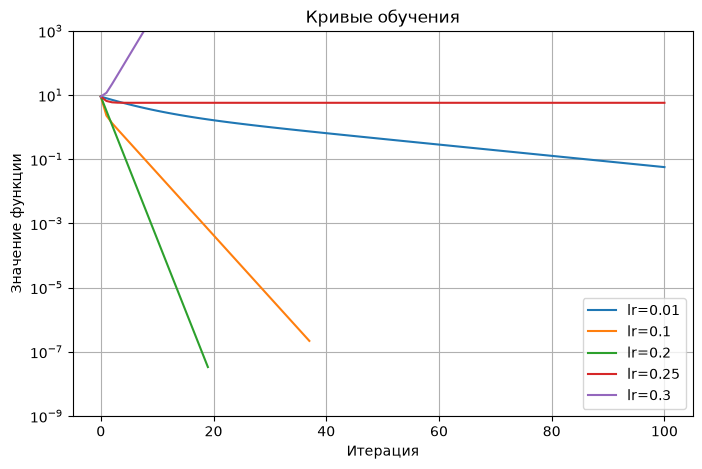

In [38]:
# это написал codex GPT-5.6 Sol

plt.figure(figsize=(8, 5))

for label, history in results_quadratic.items():
    plt.plot(
        range(len(history['loss'])),
        history['loss'],
        label=label
    )

plt.yscale('log')
plt.ylim(1e-9, 1e3)

plt.xlabel('Итерация')
plt.ylabel('Значение функции')
plt.title('Кривые обучения')
plt.legend()
plt.grid()

plt.show()

**Ваш ответ:**

по tol остановились η = 0.1 - за 37 итераций и η = 0.2 - за 19. При η = 0.01 шаг слишком маленлкий и 100 шагов не хватило.

при η = 0.2 x_new = 0.6x, y_new = -0.6y поэтому по y точка прыгает образуя зигзаг.

при η = 0.25 y_new = y - 0.25 * 8y = -y, значение y постоянно прыгает между 1.2 и -1.2 и не приближается к нулю.
ф-ция остается около 5.76 - это не сходимость.

при η = 0.3 y_new = y - 0.3 * 8y = -1.4y, траектория отдаляется от минимума т.к |y_new| > |y| на каждом шагу. Градиентный спуск расходится.

По формулам x{k+1} = (1 - 2η)x_k и y_{k+1} = (1 - 8η)y_k координата стремится к нулю, если модуль множителя меньше 1. Для x получаем |1 - 2η| < 1, то есть 0 < η < 1, а для y |1 - 8η| < 1, то есть 0 < η < 0.25. Поэтому допустимый шаг ограничивает более крутое направление y, а скорость сходимости ограничивает более пологое направление x.

### Задание 2.4. Шаг обучения на функции Розенброка (0.5 балла)

Теперь невыпуклая функция Розенброка ($a = 1$, $b = 100$, минимум в точке $(1, 1)$).

1. **(0.15)** Для каждого шага из `learning_rates_rosen` запустите спуск из точки `(-1.5, 2.0)` с `n_iterations=10000` и `tol=1e-3`. Истории сохраните в словарь `results_rosen`, выведите число итераций, финальное значение функции и финальную точку. Если увидите предупреждение `RuntimeWarning: overflow` — это не ошибка в коде, а признак того, что спуск разошёлся.
2. Запустите готовую ячейку с графиками.
3. **(0.1)** Постройте кривые обучения для всех шагов (логарифмическая шкала по $y$). Расходящийся запуск улетает к огромным значениям и растягивает ось — ограничьте её, например `plt.ylim(1e-7, 1e4)`, чтобы остальные кривые было видно.
4. **(0.25)** Ответьте на вопросы:
   - При каком $\eta$ спуск остановился по `tol` около минимума? Сколько итераций понадобилось?
   - Как выглядит траектория: как спуск ведёт себя в начале и как — на дне «оврага»? Почему по дну оврага он движется так медленно?
   - Что произошло при $\eta = 0.0025$?
   - В задании 2.3 хорошо работал шаг 0.1. Почему здесь нельзя взять такой же? Подсказка: сравните норму градиента двух функций в стартовых точках (первое значение в `history['grad_norm']`).

In [39]:
learning_rates_rosen = [0.0001, 0.0005, 0.001, 0.0018, 0.0025]
start_rosen = np.array([-1.5, 2.0])
results_rosen = {}

for lr in learning_rates_rosen:
    gd = GradientDescent(learning_rate=lr, n_iterations=10000, tol=1e-3)
    params = gd.fit(rosenbrock_loss, rosenbrock_grad, start_rosen)
    results_rosen[f'lr={lr}'] = gd.history
    print(f"Learning rate: {lr}, iterations: {len(gd.history['loss']) - 1}, last function: {gd.history['loss'][-1]}, Resulting params: {params}")

Learning rate: 0.0001, iterations: 10000, last function: 2.7817561589716813, Resulting params: [-0.66593918  0.45147674]
Learning rate: 0.0005, iterations: 10000, last function: 0.006545252794798543, Resulting params: [0.91916852 0.84453129]
Learning rate: 0.001, iterations: 10000, last function: 9.615586364352622e-05, Resulting params: [0.99020202 0.98046061]
Learning rate: 0.0018, iterations: 8229, last function: 1.249133346669188e-06, Resulting params: [0.99888325 0.99776327]
Learning rate: 0.0025, iterations: 8, last function: inf, Resulting params: [-2.25815965e+119  1.85412823e+079]


C:\Users\Максим\AppData\Local\Temp\ipykernel_18640\2491766454.py:16: RuntimeWarning: overflow encountered in scalar power
  return (a - x)**2 + b*(y - x**2)**2
C:\Users\Максим\AppData\Local\Temp\ipykernel_18640\2491766454.py:22: RuntimeWarning: overflow encountered in scalar multiply
  return np.array([-2*(a - x) - 4*b*x*(y - x**2), 2*b*(y - x**2)])
c:\Users\Максим\OneDrive\Рабочий стол\ml hse\.venv\Lib\site-packages\numpy\linalg\_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


In [40]:
x_range = np.linspace(-2, 2, 150)
y_range = np.linspace(-1, 3, 150)

plot_gd_2d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска (3D)', min_point=(1, 1))

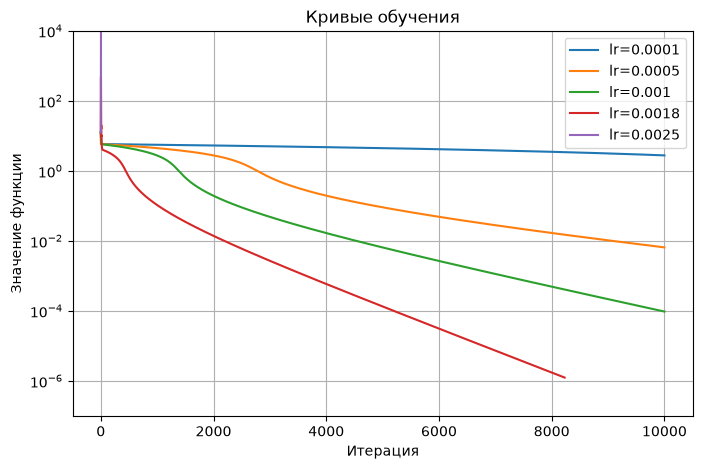

In [41]:
plt.figure(figsize=(8, 5))

for label, history in results_rosen.items():
    plt.plot(
        range(len(history['loss'])),
        history['loss'],
        label=label
    )

plt.yscale('log')
plt.ylim(1e-7, 1e4)

plt.xlabel('Итерация')
plt.ylabel('Значение функции')
plt.title('Кривые обучения')
plt.legend()
plt.grid()

plt.show()

In [42]:
quadratic_start_norm = np.linalg.norm(quadratic_grad(start_quadratic))
rosen_start_norm = np.linalg.norm(rosenbrock_grad(start_rosen))

print('Норма градиента квадратичной функции:', quadratic_start_norm)
print('Норма градиента функции Розенброка:', rosen_start_norm)

Норма градиента квадратичной функции: 10.252804494381037
Норма градиента функции Розенброка: 162.8649747490233


**Ваш ответ:**
по tol остановился только η = 0.0018 на графике видно что он остановился после примерно 8200 итераций.

В начале спуск быстро попадает на дно узкого оврага, а затем медленно движется вдоль него к точке минимума. По дну движение медленное, потому что поперёк оврага градиент большой, а вдоль оврага маленький.

При η = 0.0025 шаг оказался слишком большим и спуск перескочил через овраг и разошелся.

В начальной точке норма градиента квадратичной функции примерно 10.25, а функции Розенброка примерно 162.86. Так что для функции Розенброка шаги градиентного спуска должны быть значительно меньше, чем для квадратичной функции.

### Задание 2.5. Расписание шага (0.75 балла)

Мы видели дилемму: большой шаг быстро двигает спуск вперёд, но не даёт «успокоиться» у минимума и может разойтись; маленький шаг устойчив, но медленный. Отсюда идея — **менять шаг по ходу обучения** (learning rate schedule): в начале шагать крупно, потом всё мельче: $\eta_k = \eta(k)$.

Популярные расписания:

- **step decay** — уменьшать шаг в $\gamma$ раз каждые несколько итераций: $\eta_k = \eta_0 \cdot \gamma^{\lfloor k / s \rfloor}$;
- **exponential decay** — $\eta_k = \eta_0 \cdot \gamma^k$, $0 < \gamma < 1$;
- **inverse time decay** — $\eta_k = \dfrac{\eta_0}{1 + \text{decay} \cdot k}$. Оно уже реализовано в вашем классе.

Сравним постоянный шаг и inverse time decay на функции Розенброка из точки `(-1.2, 1.0)`, `n_iterations=3000`, без `tol`.

1. **(0.25)** Запустите спуск с постоянным шагом $\eta = 0.003$. Затем — с тем же $\eta_0 = 0.003$ и расписанием: подберите `decay` так, чтобы финальное значение функции было **меньше 0.002**. Попробуйте несколько значений `decay` от `1e-4` до `1e-2` и выведите финальные значения для каждого. Для сравнения запустите ещё и лучший постоянный шаг из 2.4 ($\eta = 0.0018$).
2. **(0.2)** Постройте траектории готовыми функциями (постоянный 0.003, лучший `decay`, постоянный 0.0018) и два графика: кривые обучения (логарифмическая шкала) и шаг обучения $\eta_k$ по итерациям (`history['lr']`).
3. **(0.3)** Ответьте на вопросы:
   - Почему спуск с постоянным шагом 0.003 застрял? Посмотрите на траекторию вблизи дна оврага и на последние точки `history['params'][-4:]`. Дно оврага — кривая $y = x^2$.
   - Как расписание помогло с тем же стартовым шагом?
   - Что получается при слишком большом `decay`, например `1e-2`? А при слишком маленьком?
   - Сравните расписание с постоянным шагом 0.0018. Что лучше и почему?

In [43]:
start_schedule = np.array([-1.2, 1.0])

gd_const_003 = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=None, tol=None)

params_const_003 = gd_const_003.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)

history_const_003 = gd_const_003.history

print('Финальный loss:', history_const_003['loss'][-1])
print('Финальная точка:', params_const_003)

Финальный loss: 0.32572225691609175
Финальная точка: [0.73936469 0.59743332]


In [44]:
decay_list = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
results_decay = {}

for decay in decay_list:
    gd = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=decay, tol=None)
    params = gd.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
    history = gd.history
    print(f'Decay: {decay}')
    print('Финальный loss:', history['loss'][-1])
    print('Финальная точка:', params)
    results_decay[decay] = gd.history

Decay: 0.0001
Финальный loss: 0.08389950962288881
Финальная точка: [0.90160997 0.84014368]
Decay: 0.0005
Финальный loss: 0.001614883628033191
Финальная точка: [0.95984811 0.92114379]
Decay: 0.001
Финальный loss: 0.005211853833983894
Финальная точка: [0.92786976 0.86064092]
Decay: 0.005
Финальный loss: 0.06742684136523985
Финальная точка: [0.74061261 0.54730279]
Decay: 0.01
Финальный loss: 0.17208691885936173
Финальная точка: [0.58567327 0.34096311]


In [45]:
gd_best_const = GradientDescent(learning_rate=0.0018, n_iterations=3000, decay=None, tol=None)
params_best_const = gd_best_const.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
history_best_const = gd_best_const.history
print('Финальный loss:', history_best_const['loss'][-1])
print('Финальная точка:', params_best_const)

Финальный loss: 0.0025664183142612147
Финальная точка: [0.94938322 0.9011197 ]


In [46]:
schedule_results = {'const 0.003': history_const_003, 'decay 5e-4': results_decay[5e-4], 'const 0.0018': history_best_const}

plot_gd_2d(rosenbrock_loss, schedule_results, x_range, y_range, title='Функция Розенброка: траектории спуска', min_point=(1, 1))

plot_gd_3d(rosenbrock_loss, schedule_results, x_range, y_range, title='Функция Розенброка (3D): траектории спуска', min_point=(1, 1))

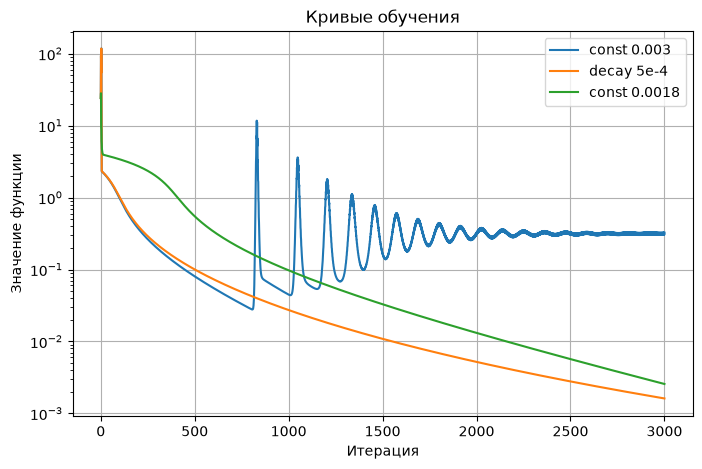

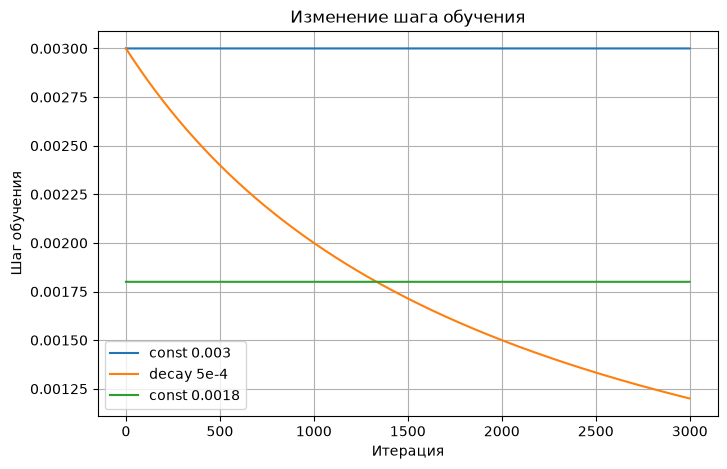

In [47]:
# это написал codex GPT-6.1 Sol

plt.figure(figsize=(8, 5))

for label, history in schedule_results.items():
    plt.plot(
        range(len(history['loss'])),
        history['loss'],
        label=label
    )

plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('Значение функции')
plt.title('Кривые обучения')
plt.legend()
plt.grid()
plt.show()


# Изменение шага обучения

plt.figure(figsize=(8, 5))

for label, history in schedule_results.items():
    plt.plot(
        range(len(history['lr'])),
        history['lr'],
        label=label
    )

plt.xlabel('Итерация')
plt.ylabel('Шаг обучения')
plt.title('Изменение шага обучения')
plt.legend()
plt.grid()
plt.show()

In [48]:
np.array(history_const_003['params'][-4:])

array([[0.78595422, 0.56697099],
       [0.73937101, 0.59742281],
       [0.78596543, 0.56697082],
       [0.73936469, 0.59743332]])

**Ваш ответ:**

При постоянном шаге 0.003 последние точки чередуются между двумя значениями, не сходясь к минимуму. Спуск не сходится а прыгает между сторонами оврага, шаг слишком большой что бы остановиться на дне оврага.

Расписание постепенно уменьшает шаг 0.003, поэтому в начале спуск движется быстро, а около минимума перестаёт прыгать между стенками оврага. В результате с decay = 5e-4 финальный loss снизился до 0.001615.

При слишком большом decay = 1e-2 шаг уменьшается слишком быстро, поэтому спуск почти останавливается далеко от минимума, не успев достичь его (loss = 0.172). При слишком маленьком decay = 1e-4 шаг долго остаётся большим и спуск продолжает колебаться, loss равен 0.084. Лучшим оказался промежуточный decay = 5e-4.

Расписание с decay = 5e-4 лучше постоянного шага 0.0018: финальный loss равен 0.001615 против 0.002566. Большой начальный шаг ускоряет движение, а его постепенное уменьшение помогает точнее приблизиться к минимуму.

### Задание 2.6. Градиентный спуск для линейной регрессии (1 балл)

Вернёмся к машинам и обучим линейную регрессию из 1.4 своим `GradientDescent`.

Добавим к признакам столбец из единиц — тогда свободный член (intercept) станет обычным весом $w_0$. Для матрицы признаков $X$ размера $n \times (d+1)$ и вектора весов $w$:
$$L(w) = \frac{1}{n}\,\|Xw - y\|^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i^\top w - y_i)^2, \qquad \nabla L(w) = \frac{2}{n}\,X^\top (Xw - y).$$

1. **(0.25)** Реализуйте `mse_loss(w, X, y)` и `mse_grad(w, X, y)` по этим формулам — без циклов, через матричные операции NumPy (`@` — матричное умножение, `.T` — транспонирование).
2. **(0.25)** Запустите спуск из $w_0 = 0$ (`np.zeros(X_gd.shape[1])`) на `X_gd`, `y_gd` из ячейки ниже для шагов `[0.01, 0.1, 0.3, 0.5]` с `n_iterations=1000` и `tol=1`. Класс ожидает функции от одного аргумента `w`, поэтому передавайте `lambda w: mse_loss(w, X_gd, y_gd)` (и так же для градиента). Выведите для каждого шага число итераций и финальный loss, постройте кривые обучения (логарифмическая шкала; у расходящегося запуска в истории окажется `inf`, поэтому задайте пределы оси, например `plt.ylim(1e11, 1e13)`). При каком шаге спуск разошёлся?
3. **(0.25)** Сравните веса лучшего запуска с `lin_reg_scaled` из 1.4 (`intercept_` и `coef_`), сведите их в таблицу. Посчитайте $R^2$ своей модели на test: не забудьте добавить столбец единиц к `X_test_scaled`.
4. **(0.25)** Повторите спуск на **нестандартизированных** признаках: `X_train` из 1.1 со столбцом единиц, шаг `1e-10`, 1000 итераций (с шагом побольше спуск расходится, можете проверить). Сравните финальный loss с результатом на стандартизированных признаках. Почему без стандартизации спуск не справляется? Свяжите ответ с заданием 2.3.

In [49]:
# матрица признаков со столбцом единиц (для intercept) и таргет в виде массивов NumPy
X_gd = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
y_gd = y_train.to_numpy()
print(X_gd.shape, y_gd.shape)

(5843, 7) (5843,)


In [50]:
def mse_loss(w, X, y):
    return ((X @ w - y) ** 2).mean()


def mse_grad(w, X, y):
    return 2 * X.T @ (X @ w - y) / X.shape[0]

In [51]:
# Проверка. Для квадратичной функции центральная разность точна при любом h, поэтому берём h=1
w_check = np.arange(X_gd.shape[1], dtype=float)
assert np.isclose(mse_loss(w_check, X_gd, y_gd), mean_squared_error(y_gd, X_gd @ w_check)), 'mse_loss считает неверно'
assert np.allclose(mse_grad(w_check, X_gd, y_gd),
                   numerical_grad(lambda w: mse_loss(w, X_gd, y_gd), w_check, h=1.0), rtol=1e-6), 'mse_grad считает неверно'
print('mse_loss и mse_grad посчитаны верно.')

mse_loss и mse_grad посчитаны верно.


In [52]:
learning_rates_linreg = [0.01, 0.1, 0.3, 0.5]
results_linreg = {}

for lr in learning_rates_linreg:
    initial_w = np.zeros(X_gd.shape[1])
    gd = GradientDescent(learning_rate=lr, n_iterations=1000, tol=1)

    final_w = gd.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad(w, X_gd, y_gd), initial_w)
    results_linreg[f'lr={lr}'] = gd.history
    
    print(
        f'lr={lr}, '
        f'итераций={len(gd.history["loss"]) - 1}, '
        f'финальный loss={gd.history["loss"][-1]}'
    )
    

lr=0.01, итераций=1000, финальный loss=116853792539.47372
lr=0.1, итераций=318, финальный loss=116851699648.09013
lr=0.3, итераций=103, финальный loss=116851699647.9494
lr=0.5, итераций=727, финальный loss=inf


c:\Users\Максим\OneDrive\Рабочий стол\ml hse\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


c:\Users\Максим\OneDrive\Рабочий стол\ml hse\.venv\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


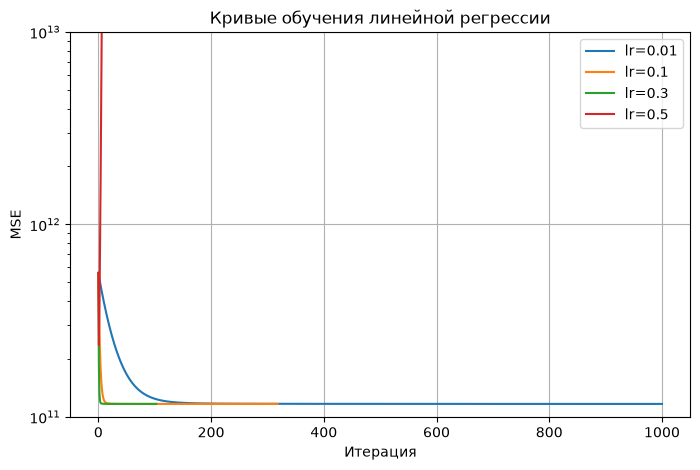

In [53]:
# эиу ячейку написал codex GPT-6.1 Sol

plt.figure(figsize=(8, 5))

for label, history in results_linreg.items():
    plt.plot(
        range(len(history['loss'])),
        history['loss'],
        label=label
    )

plt.yscale('log')
plt.ylim(1e11, 1e13)

plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Кривые обучения линейной регрессии')
plt.legend()
plt.grid()
plt.show()

In [54]:
w_gd = np.array(results_linreg['lr=0.3']['params'][-1])

w_sklearn = np.concatenate([[model_scaled.intercept_], model_scaled.coef_])

print('Веса своего GD:', w_gd)
print('Веса sklearn:', w_sklearn)

Веса своего GD: [522967.8131097  152898.69638331 -43954.0297122   28791.92233767
  61373.29203789 322548.70850563 -23442.27350137]
Веса sklearn: [522967.8131097  152898.49820482 -43953.85356576  28791.81694956
  61371.07288445 322550.13607725 -23441.05486592]


In [55]:
feature_names = ['intercept'] + list(X_train.columns)

weights_comparison = pd.DataFrame({'Признак': feature_names, 'Свой GD': w_gd, 'sklearn': w_sklearn, 'Разница': w_gd - w_sklearn})

display(weights_comparison)

X_test_gd = np.hstack([np.ones((X_test_scaled.shape[0], 1)),X_test_scaled])

y_test_pred_gd = X_test_gd @ w_gd
r2_test_gd = r2_score(y_test, y_test_pred_gd)

print('R² своего GD на test:', r2_test_gd)

,Признак,Свой GD,sklearn,Разница
0,intercept,522967.813110,522967.813110,-5.820766e-11
1,year,152898.696383,152898.498205,1.981785e-01
2,km_driven,-43954.029712,-43953.853566,-1.761464e-01
3,mileage,28791.922338,28791.816950,1.053881e-01
4,engine,61373.292038,61371.072884,2.219153e+00
5,max_power,322548.708506,322550.136077,-1.427572e+00
6,seats,-23442.273501,-23441.054866,-1.218635e+00


R² своего GD на test: 0.5939744451083097


In [56]:
X_gd_unscaled = np.hstack([np.ones((X_train.shape[0], 1)),X_train.to_numpy()])

print(X_gd_unscaled.shape)
print(y_gd.shape)

(5843, 7)
(5843,)


In [57]:
gd_unscaled = GradientDescent(learning_rate=1e-10, n_iterations=1000, tol=None)

initial_w_unscaled = np.zeros(X_gd_unscaled.shape[1])

w_unscaled = gd_unscaled.fit(lambda w: mse_loss(w, X_gd_unscaled, y_gd), lambda w: mse_grad(w, X_gd_unscaled, y_gd), initial_w_unscaled)

history_unscaled = gd_unscaled.history

print('Финальный loss без стандартизации:', history_unscaled['loss'][-1])

Финальный loss без стандартизации: 317025976603.0677


In [58]:
loss_scaled = results_linreg['lr=0.3']['loss'][-1]
loss_unscaled = history_unscaled['loss'][-1]

print('Loss со стандартизацией:', loss_scaled)
print('Loss без стандартизации:', loss_unscaled)
print('Во сколько раз хуже:', loss_unscaled / loss_scaled)


Loss со стандартизацией: 116851699647.9494
Loss без стандартизации: 317025976603.0677
Во сколько раз хуже: 2.7130626046365007


**Ваш ответ:**

Спуск разошелся при η = 0.5.

Веса лучшего запуска с η = 0.3 почти совпали с весами LinearRegression.

R² на test равен 0.594.

Без стандартизации признаки имеют разные масштабы, поэтому допустимый шаг ограничивается самым крупным и крутым направлением, а по остальным направлениям спуск движется слишком медленно (loss без стандартизации в 2.7 раза больше чем с ней) как в задании 2.3.

### Задание 2.7. Стохастический градиентный спуск (0.5 балла)

В стохастическом (mini-batch) градиентном спуске (SGD) градиент на каждом шаге считаем не по всей выборке, а по небольшому случайному подмножеству объектов — **батчу** (batch). Шаг становится намного дешевле, но градиент — шумным.

Нашему классу можно просто передать другую функцию градиента. Loss при этом по-прежнему считается по всей выборке, так кривые обучения удобно сравнивать.

1. **(0.2)** Допишите `mse_grad_batch(w, batch_size)`: выберите `batch_size` случайных номеров объектов без повторов (`rng.choice(n, size=batch_size, replace=False)`) и верните градиент MSE только по этим объектам (используйте `mse_grad`).
2. **(0.15)** Обучите SGD на `X_gd`, `y_gd` с `batch_size` 1, 32 и 256: шаг 0.01, 1000 итераций, `tol=None`. Постройте кривые обучения вместе с полным GD с тем же шагом.
3. **(0.15)** Ответьте: как размер батча влияет на вид кривой и на финальный loss? Почему для SGD не годится критерий остановки по норме градиента?

In [59]:
rng = np.random.default_rng(42)


def mse_grad_batch(w, batch_size):
    n = X_gd.shape[0]

    idx = rng.choice(n, batch_size, replace=False)
    X_batch = X_gd[idx]
    y_batch = y_gd[idx]
    return mse_grad(w, X_batch, y_batch)


In [60]:
batch_sizes = [1, 32, 256]
results_sgd = {}

for batch_size in batch_sizes:
    gd_sgd = GradientDescent(learning_rate=0.01, n_iterations=1000, tol=None)
    gd_sgd.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w, bs=batch_size: mse_grad_batch(w, bs), np.zeros(X_gd.shape[1]))
    results_sgd[f'batch={batch_size}'] = gd_sgd.history
    print(
        f'batch={batch_size}, '
        f'финальный loss={gd_sgd.history["loss"][-1]}'
    )

batch=1, финальный loss=335809120100.582
batch=32, финальный loss=117143543899.81067
batch=256, финальный loss=116962161133.24014


In [61]:
# этот код писал codex GPT-6.1 Sol

gd_full = GradientDescent(
    learning_rate=0.01,
    n_iterations=1000,
    tol=None
)

gd_full.fit(
    lambda w: mse_loss(w, X_gd, y_gd),
    lambda w: mse_grad(w, X_gd, y_gd),
    np.zeros(X_gd.shape[1])
)

history_full_gd = gd_full.history

print(
    'Полный GD, финальный loss:',
    history_full_gd['loss'][-1]
)


Полный GD, финальный loss: 116853792539.47372


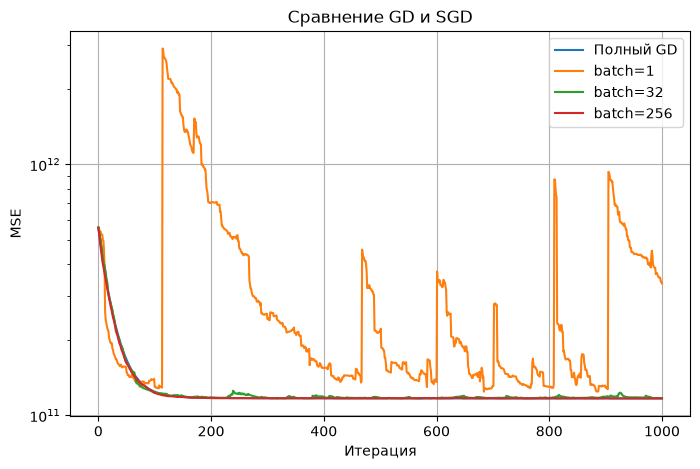

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_full_gd['loss'],
    label='Полный GD'
)

for label, history in results_sgd.items():
    plt.plot(
        history['loss'],
        label=label
    )

plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Сравнение GD и SGD')
plt.legend()
plt.grid()
plt.show()

**Ваш ответ:**

Чем меньше батч тем больше шума. При batch=1 кривая сильно скачет, а финальный loss получился самым большим. При увеличении размера батча кривая становится более гладкой, а финальный loss приближается к результату полного GD. Лучший результат получился при batch=256.

Градиент считается по случайному батчу, поэтому его норма сильно меняется. Она может случайно стать маленькой далеко от минимума или оставаться большой рядом с ним. Поэтому остановка по tol может сработать слишком рано или вообще не сработать.


## Чек-лист перед сдачей

- [X] Перезапустил ядро и выполнил все ячейки сверху вниз — ошибок нет.
- [X] Все выводы и графики сохранены в ноутбуке.
- [X] Ответил текстом на все вопросы.
- [X] Если пользовался LLM или чужим кодом, указал это.

В целом использовал GPT для подсказок по ходу выполнения домашнего задания. Но весь написанный им код указал в ячейках.